# Overview

This notebook analyzes 30-day hospital readmission risk using the UCI Diabetes 130-US Hospitals dataset. Place `diabetic_data.csv` and `IDS_mapping.csv` in `data/raw/` before running it. To make charts, tables, and narrative outputs visible on GitHub, run the notebook locally and save the executed outputs into the notebook file before committing.

# Data source & business context

# Load data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 60)

# Resolve paths robustly whether the notebook is run from the repo root or notebooks/
candidate_roots = [
    os.getcwd(),
    os.path.abspath(os.path.join(os.getcwd(), "..")),
]

DATA_PATH = None
MAPPING_PATH = None

for root in candidate_roots:
    candidate_data = os.path.join(root, "data", "raw", "diabetic_data.csv")
    candidate_map = os.path.join(root, "data", "raw", "IDS_mapping.csv")
    if os.path.exists(candidate_data) and os.path.exists(candidate_map):
        DATA_PATH = candidate_data
        MAPPING_PATH = candidate_map
        break

print("Current working directory:", os.getcwd())

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find diabetic_data.csv and IDS_mapping.csv in data/raw/ "
        "from either the current directory or its parent."
    )

print("Using main dataset:", DATA_PATH)
print("Using mapping dataset:", MAPPING_PATH)

df = pd.read_csv(DATA_PATH)
ids_map = pd.read_csv(MAPPING_PATH)

print("df shape:", df.shape)
print("ids_map shape:", ids_map.shape)
print("Columns in diabetic_data.csv:")
print(df.columns.tolist())

display(df.head())
display(ids_map.head())


Current working directory: /Users/ahannair/Desktop/DiabetesReadmissionAnalysis/notebooks
Using main dataset: /Users/ahannair/Desktop/DiabetesReadmissionAnalysis/data/raw/diabetic_data.csv
Using mapping dataset: /Users/ahannair/Desktop/DiabetesReadmissionAnalysis/data/raw/IDS_mapping.csv
df shape: (101766, 50)
ids_map shape: (67, 2)
Columns in diabetic_data.csv:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipt

,encounter_id,patient_nbr,race,gender,age,weight,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,...,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,...,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,...,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,...,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,...,No,No,No,Ch,Yes,NO


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available


# Data dictionary & target definition

In [2]:
fields = [
    "encounter_id",
    "patient_nbr",
    "race",
    "gender",
    "age",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "payer_code",
    "medical_specialty",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "diag_1",
    "diag_2",
    "diag_3",
    "max_glu_serum",
    "A1Cresult",
    "insulin",
    "change",
    "diabetesMed",
    "readmitted",
    "readmit_30d",
]

field_usage = {
    "encounter_id": "record identifier",
    "patient_nbr": "patient identifier",
    "race": "demographic feature",
    "gender": "demographic feature",
    "age": "demographic feature",
    "admission_type_id": "encounter context feature",
    "discharge_disposition_id": "encounter outcome feature",
    "admission_source_id": "encounter context feature",
    "time_in_hospital": "utilization feature",
    "payer_code": "administrative feature",
    "medical_specialty": "provider context feature",
    "num_lab_procedures": "utilization feature",
    "num_procedures": "utilization feature",
    "num_medications": "treatment intensity feature",
    "number_outpatient": "prior utilization feature",
    "number_emergency": "prior utilization feature",
    "number_inpatient": "prior utilization feature",
    "diag_1": "clinical diagnosis feature",
    "diag_2": "clinical diagnosis feature",
    "diag_3": "clinical diagnosis feature",
    "max_glu_serum": "lab result feature",
    "A1Cresult": "lab result feature",
    "insulin": "medication feature",
    "change": "medication change feature",
    "diabetesMed": "medication indicator",
    "readmitted": "original outcome field",
    "readmit_30d": "binary modeling target",
}

field_notes = {
    "encounter_id": "unique encounter identifier",
    "patient_nbr": "patient-level identifier; can repeat across encounters",
    "race": "categorical patient race field",
    "gender": "categorical patient gender field",
    "age": "recorded as age bands",
    "admission_type_id": "coded field; refer to IDS mapping file",
    "discharge_disposition_id": "coded field; refer to IDS mapping file",
    "admission_source_id": "coded field; refer to IDS mapping file",
    "time_in_hospital": "length of stay in days",
    "payer_code": "often sparse in this dataset",
    "medical_specialty": "often sparse and high-cardinality",
    "num_lab_procedures": "count of lab procedures during encounter",
    "num_procedures": "count of procedures during encounter",
    "num_medications": "count of medications during encounter",
    "number_outpatient": "historical outpatient visits",
    "number_emergency": "historical emergency visits",
    "number_inpatient": "historical inpatient visits",
    "diag_1": "primary diagnosis code",
    "diag_2": "secondary diagnosis code",
    "diag_3": "tertiary diagnosis code",
    "max_glu_serum": "glucose serum test result category",
    "A1Cresult": "A1C test result category",
    "insulin": "insulin medication status",
    "change": "whether diabetes medications changed",
    "diabetesMed": "whether any diabetes medication was prescribed",
    "readmitted": "multiclass outcome in source data (<30, >30, NO)",
    "readmit_30d": "engineered target derived from readmitted",
}

data_dictionary = pd.DataFrame(
    {
        "field": fields,
        "used_for": [field_usage.get(field, "candidate feature") for field in fields],
        "notes": [field_notes.get(field, "") if field in df.columns else "not present" for field in fields],
    }
)

missing_values_summary = (
    pd.DataFrame(
        {
            "field": df.columns,
            "missing_count": df.isna().sum().values,
            "missing_pct": (df.isna().mean().values * 100).round(2),
        }
    )
    .sort_values(["missing_count", "field"], ascending=[False, True])
    .reset_index(drop=True)
)

display(data_dictionary)
display(missing_values_summary)


,field,used_for,notes
0,encounter_id,record identifier,unique encounter identifier
1,patient_nbr,patient identifier,patient-level identifier; can repeat across encounters
2,race,demographic feature,categorical patient race field
3,gender,demographic feature,categorical patient gender field
4,age,demographic feature,recorded as age bands
5,admission_type_id,encounter context feature,coded field; refer to IDS mapping file
6,discharge_disposition_id,encounter outcome feature,coded field; refer to IDS mapping file
7,admission_source_id,encounter context feature,coded field; refer to IDS mapping file
8,time_in_hospital,utilization feature,length of stay in days
9,payer_code,administrative feature,often sparse in this dataset


,field,missing_count,missing_pct
0,max_glu_serum,96420,94.75
1,A1Cresult,84748,83.28
2,acarbose,0,0.00
3,acetohexamide,0,0.00
4,admission_source_id,0,0.00
5,admission_type_id,0,0.00
6,age,0,0.00
7,change,0,0.00
8,chlorpropamide,0,0.00
9,citoglipton,0,0.00


**Target definition:** `readmit_30d = 1` when `readmitted == "<30"` and `0` otherwise.

# Cleaning & preprocessing

In [3]:
shape_before_cleaning = df.shape

df_clean = df.replace("?", np.nan).copy()

if "gender" in df_clean.columns:
    df_clean = df_clean[df_clean["gender"] != "Unknown/Invalid"].copy()

if "readmit_30d" not in df_clean.columns:
    if "readmitted" not in df_clean.columns:
        raise KeyError("Neither 'readmit_30d' nor 'readmitted' is available for target creation.")
    df_clean["readmit_30d"] = (df_clean["readmitted"] == "<30").astype(int)

if "age" not in df_clean.columns:
    raise KeyError("Column 'age' is missing from df_clean.")

df_clean["age_band_clean"] = (
    df_clean["age"]
    .astype(str)
    .str.strip()
    .str.replace("[", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("-", " to ", regex=False)
)

shape_after_cleaning = df_clean.shape

print("Shape before cleaning:", shape_before_cleaning)
print("Shape after cleaning:", shape_after_cleaning)
print("readmit_30d class balance:")
print(df_clean["readmit_30d"].value_counts(dropna=False))

modeling_key_fields = [
    "race",
    "gender",
    "age",
    "age_band_clean",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "payer_code",
    "medical_specialty",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "diag_1",
    "diag_2",
    "diag_3",
    "max_glu_serum",
    "A1Cresult",
    "insulin",
    "change",
    "diabetesMed",
    "readmit_30d",
]

available_modeling_fields = [field for field in modeling_key_fields if field in df_clean.columns]
missing_key_fields_summary = (
    pd.DataFrame(
        {
            "field": available_modeling_fields,
            "missing_count": [int(df_clean[field].isna().sum()) for field in available_modeling_fields],
        }
    )
    .sort_values(["missing_count", "field"], ascending=[False, True])
    .reset_index(drop=True)
)

display(missing_key_fields_summary)


Shape before cleaning: (101766, 50)
Shape after cleaning: (101763, 52)
readmit_30d class balance:
readmit_30d
0    90406
1    11357
Name: count, dtype: int64


,field,missing_count
0,max_glu_serum,96417
1,A1Cresult,84745
2,medical_specialty,49947
3,payer_code,40255
4,race,2271
5,diag_3,1423
6,diag_2,358
7,diag_1,21
8,admission_source_id,0
9,admission_type_id,0


# Descriptive readmission analysis

Overall 30-day readmission rate: 11.16%


,age_band_clean,encounters,readmit_30d_rate
0,20 to 30,1657,0.142426
1,80 to 90,17197,0.120835
2,70 to 80,26066,0.117740
3,30 to 40,3775,0.112318
4,60 to 70,22482,0.111289
5,90 to 100,2793,0.110992
6,40 to 50,9685,0.106040
7,50 to 60,17256,0.096662
8,10 to 20,691,0.057887
9,0 to 10,161,0.018634


,gender,encounters,readmit_30d_rate
0,Female,54708,0.112452
1,Male,47055,0.110615


,race,encounters,readmit_30d_rate
0,Caucasian,76099,0.112906
1,AfricanAmerican,19210,0.112181
2,Hispanic,2037,0.104075
3,Asian,641,0.101404
4,Other,1505,0.096346
5,NaN,2271,0.082783


,admission_type_id,encounters,readmit_30d_rate
0,1,53988,0.115229
1,2,18480,0.111797
2,6,5291,0.110754
3,3,18868,0.103933
4,5,4785,0.103448
5,4,10,0.100000
6,8,320,0.084375
7,7,21,0.000000


,discharge_disposition_id,encounters,readmit_30d_rate
0,12,3,0.666667
1,15,63,0.444444
2,9,21,0.428571
3,28,139,0.366906
4,22,1992,0.277108
5,5,1184,0.208615
6,2,2128,0.160714
7,3,13954,0.146625
8,24,48,0.145833
9,7,623,0.144462


,time_in_hospital,encounters,readmit_30d_rate
0,10,2342,0.143467
1,8,4390,0.142369
2,9,3002,0.137242
3,12,1448,0.133287
4,14,1042,0.129559
5,7,5859,0.128350
6,6,7539,0.125879
7,13,1210,0.123140
8,5,9966,0.120309
9,4,13924,0.118070


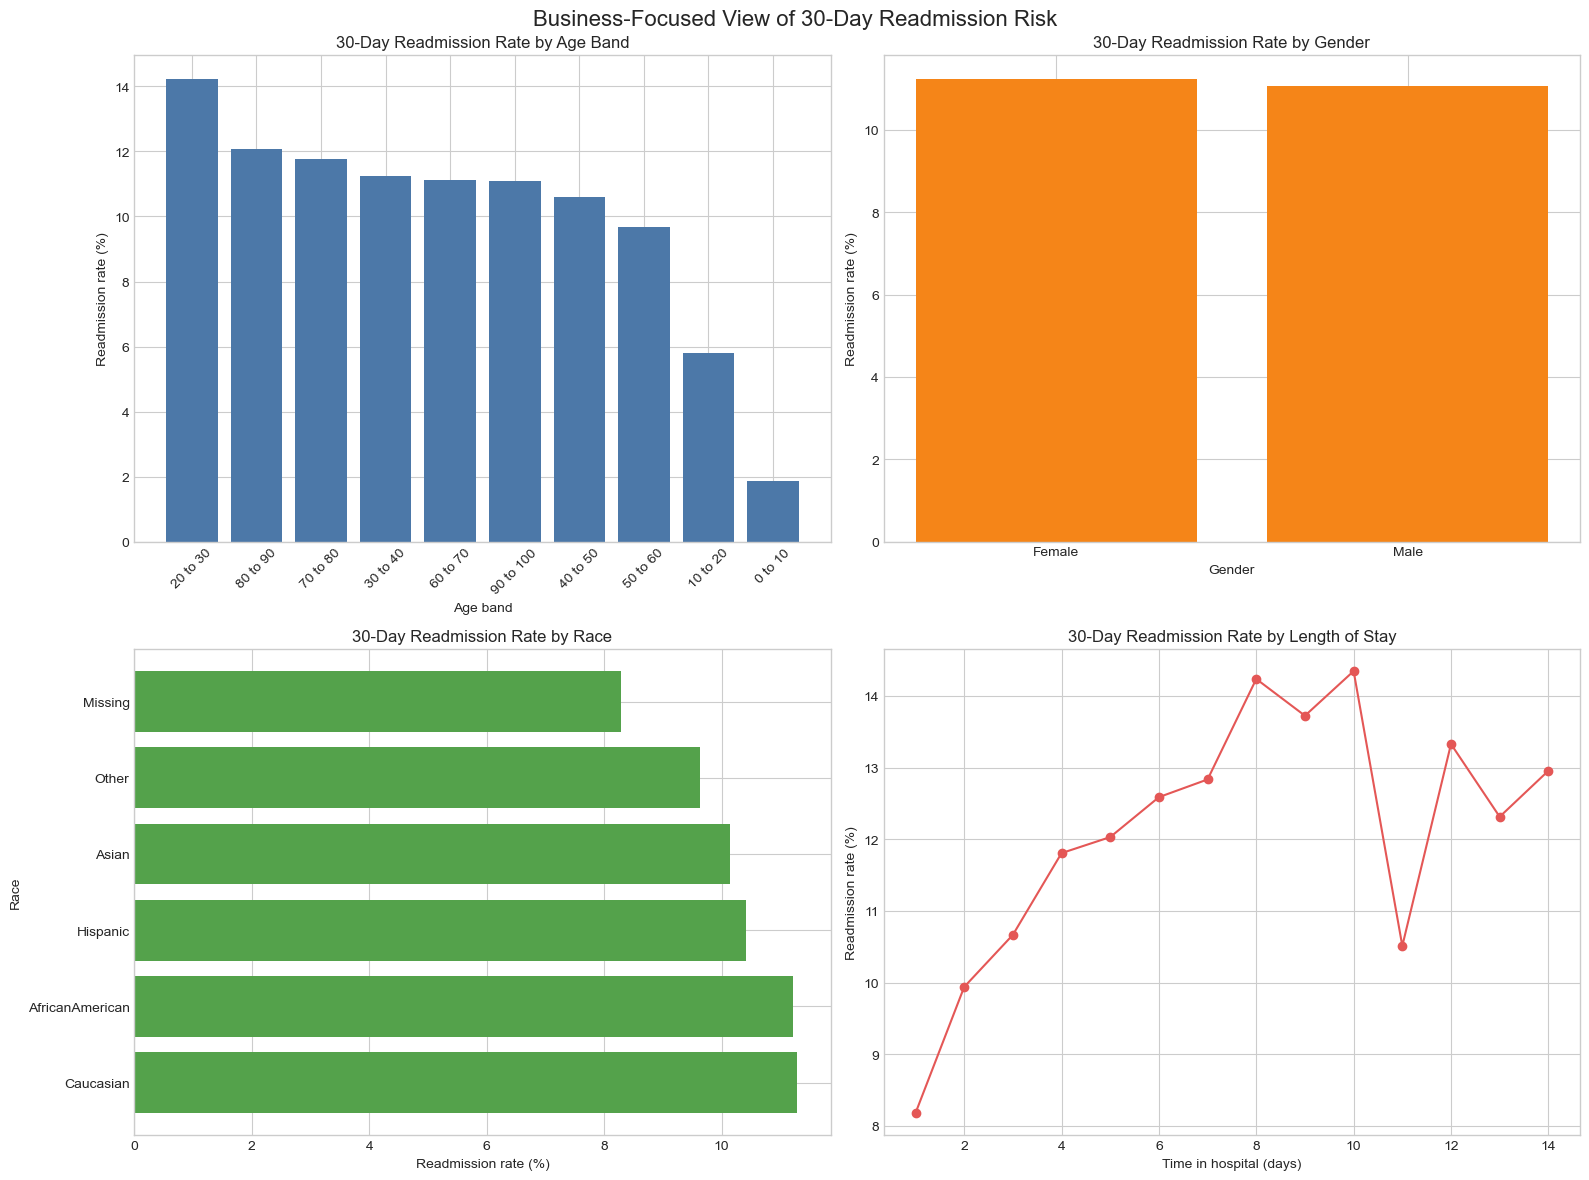

In [4]:
if "readmit_30d" not in df_clean.columns:
    raise KeyError("Column 'readmit_30d' is missing from df_clean.")

def readmission_rate_table(dataframe, group_col):
    if group_col not in dataframe.columns:
        return pd.DataFrame(columns=[group_col, "encounters", "readmit_30d_rate"])
    return (
        dataframe.groupby(group_col, dropna=False)["readmit_30d"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={"count": "encounters", "mean": "readmit_30d_rate"})
        .sort_values("readmit_30d_rate", ascending=False)
        .reset_index(drop=True)
    )

overall_readmission_rate = df_clean["readmit_30d"].mean()
age_readmission = readmission_rate_table(df_clean, "age_band_clean")
gender_readmission = readmission_rate_table(df_clean, "gender")
race_readmission = readmission_rate_table(df_clean, "race")
admission_type_readmission = readmission_rate_table(df_clean, "admission_type_id")
discharge_disposition_readmission = readmission_rate_table(df_clean, "discharge_disposition_id")
time_in_hospital_readmission = readmission_rate_table(df_clean, "time_in_hospital")

print(f"Overall 30-day readmission rate: {overall_readmission_rate:.2%}")

display(age_readmission)
display(gender_readmission)
display(race_readmission)
display(admission_type_readmission)
display(discharge_disposition_readmission)
display(time_in_hospital_readmission)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

age_plot = age_readmission.copy()
axes[0, 0].bar(age_plot["age_band_clean"].astype(str), age_plot["readmit_30d_rate"] * 100, color="#4C78A8")
axes[0, 0].set_title("30-Day Readmission Rate by Age Band")
axes[0, 0].set_xlabel("Age band")
axes[0, 0].set_ylabel("Readmission rate (%)")
axes[0, 0].tick_params(axis="x", rotation=45)

gender_plot = gender_readmission.copy()
axes[0, 1].bar(gender_plot["gender"].fillna("Missing").astype(str), gender_plot["readmit_30d_rate"] * 100, color="#F58518")
axes[0, 1].set_title("30-Day Readmission Rate by Gender")
axes[0, 1].set_xlabel("Gender")
axes[0, 1].set_ylabel("Readmission rate (%)")

race_plot = race_readmission.copy()
race_plot["race"] = race_plot["race"].fillna("Missing").astype(str)
axes[1, 0].barh(race_plot["race"], race_plot["readmit_30d_rate"] * 100, color="#54A24B")
axes[1, 0].set_title("30-Day Readmission Rate by Race")
axes[1, 0].set_xlabel("Readmission rate (%)")
axes[1, 0].set_ylabel("Race")

los_plot = time_in_hospital_readmission.sort_values("time_in_hospital")
axes[1, 1].plot(los_plot["time_in_hospital"], los_plot["readmit_30d_rate"] * 100, marker="o", color="#E45756")
axes[1, 1].set_title("30-Day Readmission Rate by Length of Stay")
axes[1, 1].set_xlabel("Time in hospital (days)")
axes[1, 1].set_ylabel("Readmission rate (%)")

plt.suptitle("Business-Focused View of 30-Day Readmission Risk", fontsize=16)
plt.tight_layout()
plt.show()


# Utilization & operational drivers


Readmission pattern for number_outpatient:


,category,encounters,readmit_30d_rate
0,40,1,1.000000
1,23,2,0.500000
2,19,3,0.333333
3,12,30,0.200000
4,22,5,0.200000
5,13,31,0.193548
6,14,28,0.178571
7,9,83,0.156627
8,7,155,0.154839
9,4,1099,0.151046



Readmission pattern for number_emergency:


,category,encounters,readmit_30d_rate
0,28,1,1.000000
1,64,1,1.000000
2,22,6,0.500000
3,19,4,0.500000
4,20,4,0.500000
5,21,2,0.500000
6,16,5,0.400000
7,9,33,0.363636
8,10,34,0.352941
9,13,12,0.333333



Readmission pattern for number_inpatient:


,category,encounters,readmit_30d_rate
0,15,9,1.000000
1,17,1,1.000000
2,21,1,1.000000
3,11,49,0.673469
4,12,34,0.500000
5,13,20,0.500000
6,19,2,0.500000
7,8,151,0.443709
8,10,61,0.426230
9,9,111,0.423423


... (10 outputs left out)


Readmission pattern for A1Cresult:


,category,encounters,readmit_30d_rate
0,Missing,84745,0.114237
1,>7,3812,0.100472
2,>8,8216,0.098710
3,Norm,4990,0.096593



Readmission pattern for change:


,category,encounters,readmit_30d_rate
0,Ch,47009,0.118233
1,No,54754,0.105910


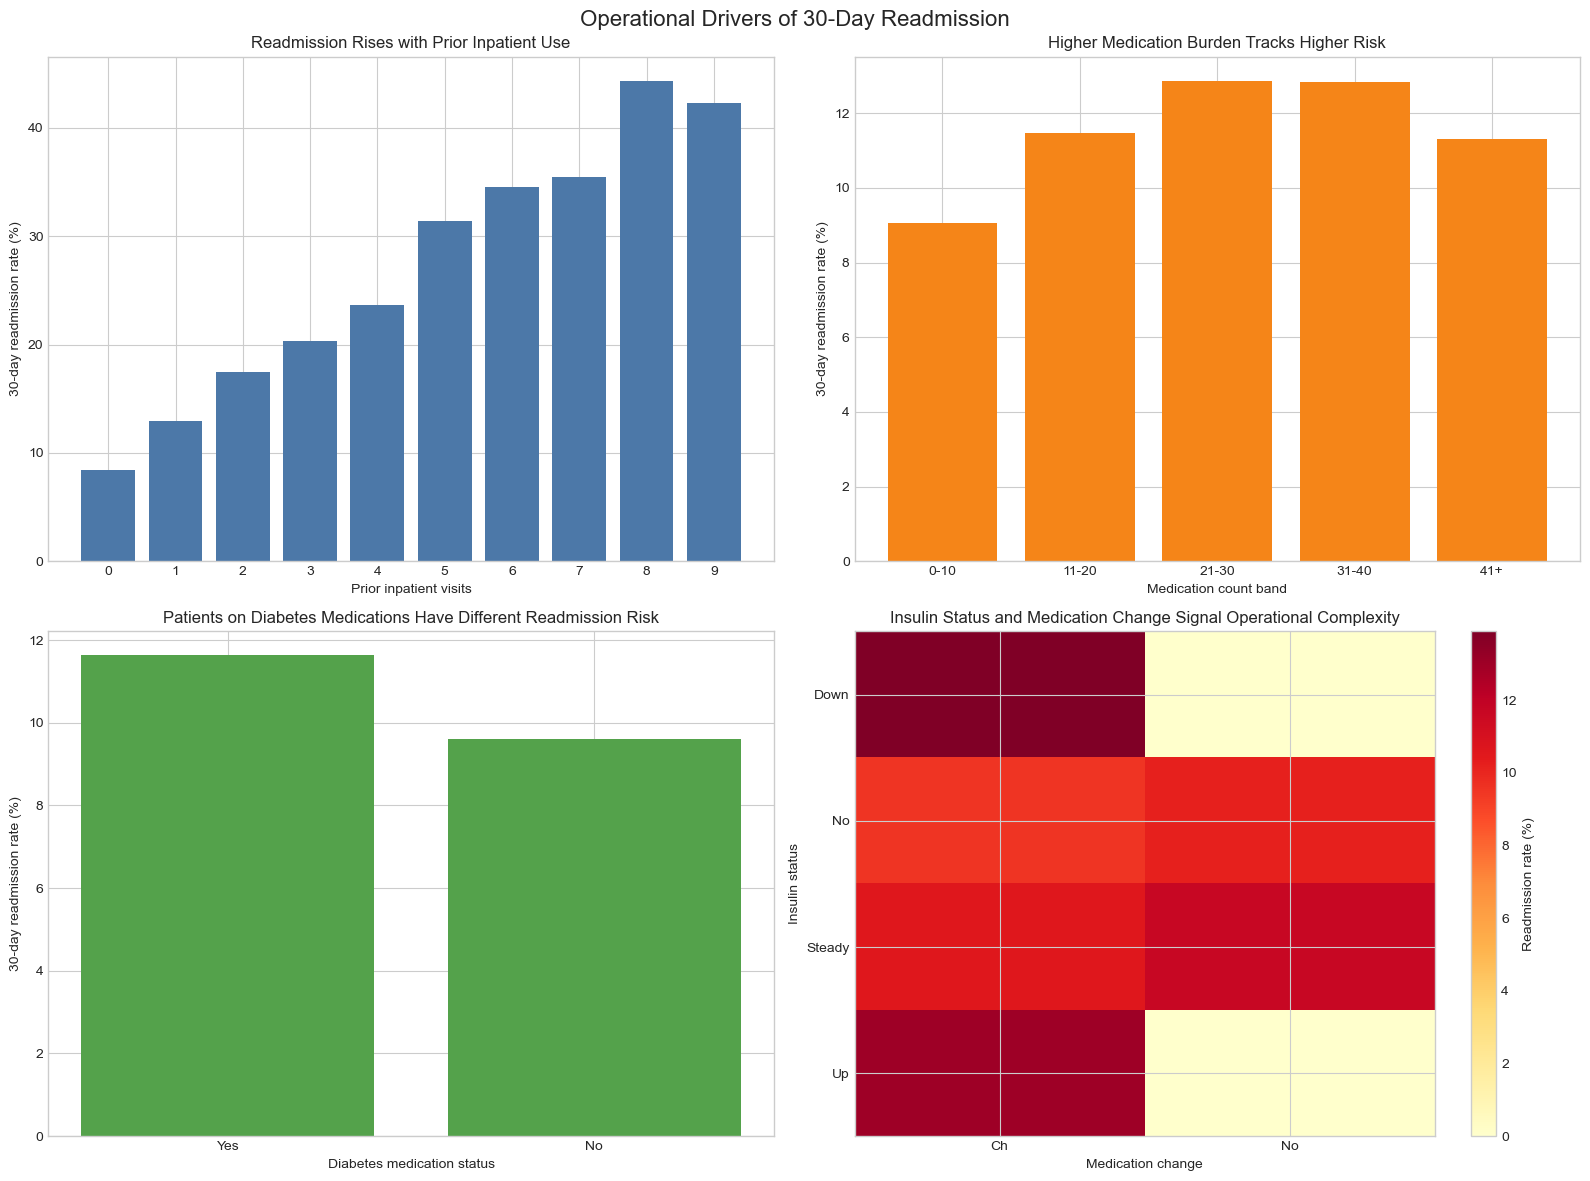

In [5]:
if "readmit_30d" not in df_clean.columns:
    raise KeyError("Column 'readmit_30d' is missing from df_clean.")

driver_fields = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "diabetesMed",
    "insulin",
    "A1Cresult",
    "change",
]

for field in driver_fields:
    if field not in df_clean.columns:
        raise KeyError(f"Column '{field}' is missing from df_clean.")

def summarize_driver(dataframe, group_col):
    summary = (
        dataframe.groupby(group_col, dropna=False)["readmit_30d"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={group_col: "category", "count": "encounters", "mean": "readmit_30d_rate"})
    )
    summary["category"] = summary["category"].fillna("Missing").astype(str)
    return summary.sort_values(["readmit_30d_rate", "encounters"], ascending=[False, False]).reset_index(drop=True)

def summarize_binned_driver(dataframe, source_col, bins, labels, ordered=True):
    binned = pd.cut(dataframe[source_col], bins=bins, labels=labels, include_lowest=True, right=True, ordered=ordered)
    summary = (
        dataframe.assign(driver_band=binned)
        .groupby("driver_band", dropna=False, observed=False)["readmit_30d"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={"driver_band": "category", "count": "encounters", "mean": "readmit_30d_rate"})
    )
    summary["category"] = summary["category"].astype(str)
    return summary

outpatient_summary = summarize_driver(df_clean, "number_outpatient")
emergency_summary = summarize_driver(df_clean, "number_emergency")
inpatient_summary = summarize_driver(df_clean, "number_inpatient")
diabetes_med_summary = summarize_driver(df_clean, "diabetesMed")
insulin_summary = summarize_driver(df_clean, "insulin")
a1c_summary = summarize_driver(df_clean, "A1Cresult")
change_summary = summarize_driver(df_clean, "change")

lab_bins = [-np.inf, 20, 40, 60, 80, np.inf]
lab_labels = ["0-20", "21-40", "41-60", "61-80", "81+"]
lab_summary = summarize_binned_driver(df_clean, "num_lab_procedures", lab_bins, lab_labels)

procedure_bins = [-np.inf, 0, 1, 3, np.inf]
procedure_labels = ["0", "1", "2-3", "4+"]
procedure_summary = summarize_binned_driver(df_clean, "num_procedures", procedure_bins, procedure_labels)

medication_bins = [-np.inf, 10, 20, 30, 40, np.inf]
medication_labels = ["0-10", "11-20", "21-30", "31-40", "41+"]
medication_summary = summarize_binned_driver(df_clean, "num_medications", medication_bins, medication_labels)

operational_driver_tables = {
    "number_outpatient": outpatient_summary,
    "number_emergency": emergency_summary,
    "number_inpatient": inpatient_summary,
    "num_lab_procedures": lab_summary,
    "num_procedures": procedure_summary,
    "num_medications": medication_summary,
    "diabetesMed": diabetes_med_summary,
    "insulin": insulin_summary,
    "A1Cresult": a1c_summary,
    "change": change_summary,
}

for field_name, summary_table in operational_driver_tables.items():
    print(f"\nReadmission pattern for {field_name}:")
    display(summary_table)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

prior_use_plot = (
    df_clean.groupby(["number_inpatient", "number_emergency", "number_outpatient"], dropna=False)["readmit_30d"]
    .mean()
)

inpatient_plot = inpatient_summary.sort_values("category", key=lambda s: pd.to_numeric(s, errors="coerce")).head(10)
axes[0, 0].bar(inpatient_plot["category"], inpatient_plot["readmit_30d_rate"] * 100, color="#4C78A8")
axes[0, 0].set_title("Readmission Rises with Prior Inpatient Use")
axes[0, 0].set_xlabel("Prior inpatient visits")
axes[0, 0].set_ylabel("30-day readmission rate (%)")

med_plot = medication_summary.copy()
axes[0, 1].bar(med_plot["category"], med_plot["readmit_30d_rate"] * 100, color="#F58518")
axes[0, 1].set_title("Higher Medication Burden Tracks Higher Risk")
axes[0, 1].set_xlabel("Medication count band")
axes[0, 1].set_ylabel("30-day readmission rate (%)")

diabetes_med_plot = diabetes_med_summary.copy()
axes[1, 0].bar(diabetes_med_plot["category"], diabetes_med_plot["readmit_30d_rate"] * 100, color="#54A24B")
axes[1, 0].set_title("Patients on Diabetes Medications Have Different Readmission Risk")
axes[1, 0].set_xlabel("Diabetes medication status")
axes[1, 0].set_ylabel("30-day readmission rate (%)")

insulin_change_plot = (
    df_clean.groupby(["insulin", "change"], dropna=False)["readmit_30d"]
    .agg(["count", "mean"])
    .reset_index()
    .rename(columns={"count": "encounters", "mean": "readmit_30d_rate"})
)
pivot_plot = insulin_change_plot.pivot(index="insulin", columns="change", values="readmit_30d_rate").fillna(0)
pivot_plot = pivot_plot.reindex(sorted(pivot_plot.index.astype(str)), axis=0)
pivot_plot = pivot_plot.reindex(sorted(pivot_plot.columns.astype(str)), axis=1)
im = axes[1, 1].imshow(pivot_plot.values * 100, cmap="YlOrRd", aspect="auto")
axes[1, 1].set_title("Insulin Status and Medication Change Signal Operational Complexity")
axes[1, 1].set_xlabel("Medication change")
axes[1, 1].set_ylabel("Insulin status")
axes[1, 1].set_xticks(range(len(pivot_plot.columns)))
axes[1, 1].set_xticklabels(pivot_plot.columns)
axes[1, 1].set_yticks(range(len(pivot_plot.index)))
axes[1, 1].set_yticklabels(pivot_plot.index)
fig.colorbar(im, ax=axes[1, 1], label="Readmission rate (%)")

plt.suptitle("Operational Drivers of 30-Day Readmission", fontsize=16)
plt.tight_layout()
plt.show()


# Modeling 30-day readmission risk

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

if "readmit_30d" not in df_clean.columns:
    raise KeyError("Column 'readmit_30d' is missing from df_clean.")

candidate_features = [
    "race",
    "gender",
    "age",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "A1Cresult",
    "insulin",
    "change",
    "diabetesMed",
]

available_features = [feature for feature in candidate_features if feature in df_clean.columns]
missing_features = [feature for feature in candidate_features if feature not in df_clean.columns]

if not available_features:
    raise ValueError("None of the requested modeling features are available in df_clean.")

modeling_df = df_clean[available_features + ["readmit_30d"]].copy()
X = modeling_df[available_features]
y = modeling_df["readmit_30d"]

categorical_features = [feature for feature in available_features if X[feature].dtype == "object"]
numeric_features = [feature for feature in available_features if feature not in categorical_features]

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_pipeline, categorical_features),
        ("numeric", numeric_pipeline, numeric_features),
    ],
    remainder="drop",
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]
)

stratify_target = y if y.nunique() > 1 else None
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_target,
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Available modeling features:", available_features)
if missing_features:
    print("Skipped missing features:", missing_features)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

metrics_summary = pd.DataFrame(
    {
        "metric": ["accuracy", "precision", "recall", "f1"],
        "value": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, zero_division=0),
            recall_score(y_test, y_pred, zero_division=0),
            f1_score(y_test, y_pred, zero_division=0),
        ],
    }
)

if y_test.nunique() > 1:
    y_score = model.predict_proba(X_test)[:, 1]
    roc_auc_value = roc_auc_score(y_test, y_score)
    metrics_summary.loc[len(metrics_summary)] = ["roc_auc", roc_auc_value]
else:
    print("ROC-AUC not reported because the test set contains only one class.")

display(metrics_summary)


Available modeling features: ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'A1Cresult', 'insulin', 'change', 'diabetesMed']
Train shape: (81410, 17)
Test shape: (20353, 17)


,metric,value
0,accuracy,0.673660
1,precision,0.172290
2,recall,0.505945
3,f1,0.257047
4,roc_auc,0.644229


# Feature interpretation

Top positive drivers of predicted 30-day readmission risk:


,feature_label,coefficient
0,number_inpatient,0.290816
1,age = [80-90),0.257527
2,age = [70-80),0.238561
3,age = [60-70),0.152230
4,age = [90-100),0.148427
5,age = [20-30),0.114430
6,insulin = Down,0.099023
7,age = [30-40),0.070859
8,number_emergency,0.066763
9,age = [40-50),0.065736


Top negative drivers of predicted 30-day readmission risk:


,feature_label,coefficient
0,age = [0-10),-0.880049
1,age = [10-20),-0.416761
2,insulin = No,-0.182490
3,diabetesMed = No,-0.177843
4,change = Ch,-0.163927
5,gender = Female,-0.123746
6,A1Cresult = >7,-0.116664
7,insulin = Steady,-0.113480
8,race = Hispanic,-0.112933
9,gender = Male,-0.098885


Plain-English interpretation for recruiter and analyst audiences:


,feature_label,plain_english
0,number_inpatient,Higher predicted readmission risk is associated with num...
1,age = [80-90),Higher predicted readmission risk is associated with age...
2,age = [70-80),Higher predicted readmission risk is associated with age...
3,age = [60-70),Higher predicted readmission risk is associated with age...
4,age = [90-100),Higher predicted readmission risk is associated with age...


,feature_label,plain_english
0,age = [0-10),Lower predicted readmission risk is associated with age ...
1,age = [10-20),Lower predicted readmission risk is associated with age ...
2,insulin = No,Lower predicted readmission risk is associated with insu...
3,diabetesMed = No,Lower predicted readmission risk is associated with diab...
4,change = Ch,Lower predicted readmission risk is associated with chan...


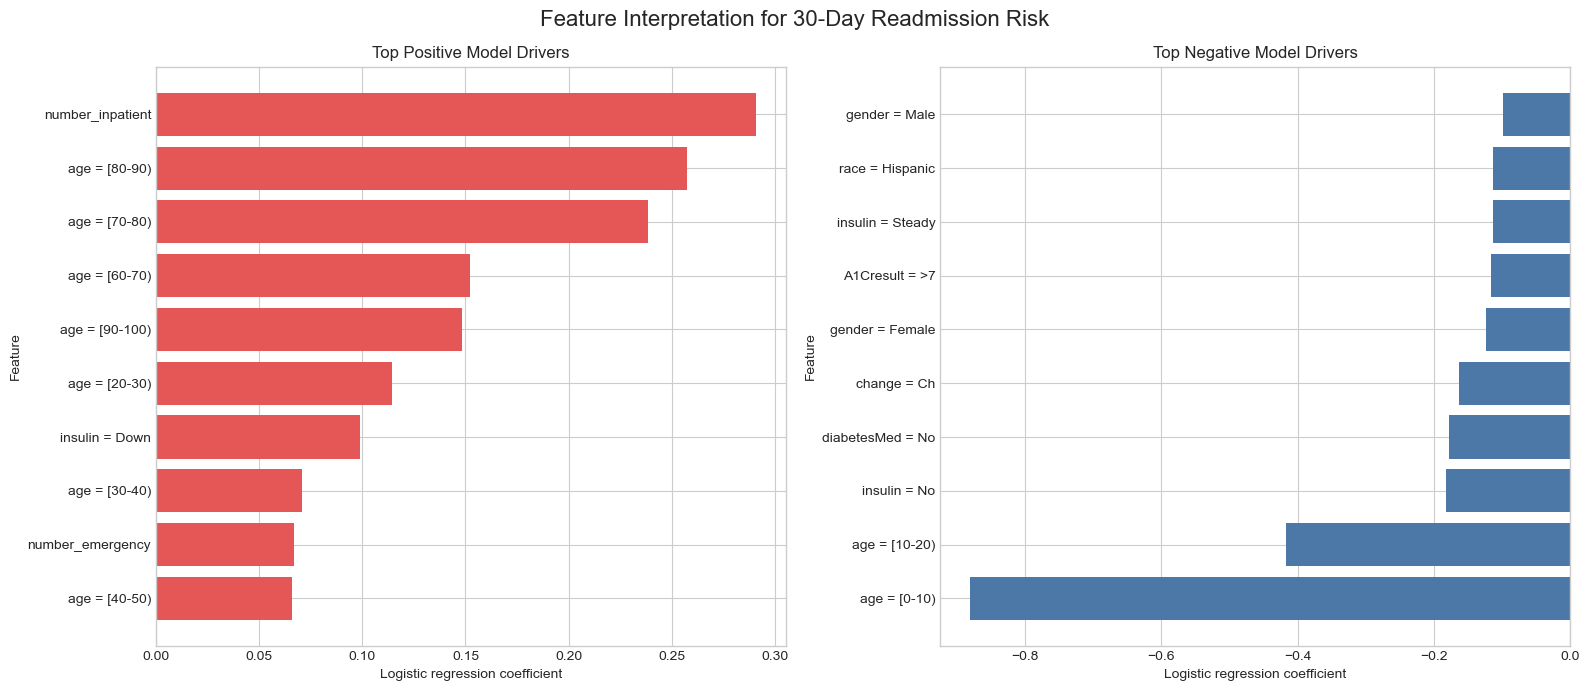

In [7]:
if "model" not in globals():
    raise NameError("Model pipeline not found. Run the modeling section first.")

fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_.ravel()

coefficient_table = (
    pd.DataFrame(
        {
            "feature": feature_names,
            "coefficient": coefficients,
        }
    )
    .assign(abs_coefficient=lambda d: d["coefficient"].abs())
    .sort_values("coefficient", ascending=False)
    .reset_index(drop=True)
)

def clean_feature_label(feature_name):
    cleaned = feature_name.replace("categorical__", "").replace("numeric__", "")
    if "_" in cleaned:
        base, value = cleaned.split("_", 1)
        if base in categorical_features:
            return f"{base} = {value}"
    return cleaned

coefficient_table["feature_label"] = coefficient_table["feature"].apply(clean_feature_label)

top_positive_drivers = coefficient_table.nlargest(10, "coefficient")[
    ["feature_label", "coefficient"]
].reset_index(drop=True)
top_negative_drivers = coefficient_table.nsmallest(10, "coefficient")[
    ["feature_label", "coefficient"]
].reset_index(drop=True)

print("Top positive drivers of predicted 30-day readmission risk:")
display(top_positive_drivers)

print("Top negative drivers of predicted 30-day readmission risk:")
display(top_negative_drivers)

positive_summary = top_positive_drivers.copy()
positive_summary["plain_english"] = positive_summary["feature_label"].apply(
    lambda x: f"Higher predicted readmission risk is associated with {x}."
)
negative_summary = top_negative_drivers.copy()
negative_summary["plain_english"] = negative_summary["feature_label"].apply(
    lambda x: f"Lower predicted readmission risk is associated with {x}."
)

print("Plain-English interpretation for recruiter and analyst audiences:")
display(positive_summary[["feature_label", "plain_english"]].head(5))
display(negative_summary[["feature_label", "plain_english"]].head(5))

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

positive_plot = top_positive_drivers.sort_values("coefficient", ascending=True)
axes[0].barh(positive_plot["feature_label"], positive_plot["coefficient"], color="#E45756")
axes[0].set_title("Top Positive Model Drivers")
axes[0].set_xlabel("Logistic regression coefficient")
axes[0].set_ylabel("Feature")

negative_plot = top_negative_drivers.sort_values("coefficient", ascending=True)
axes[1].barh(negative_plot["feature_label"], negative_plot["coefficient"], color="#4C78A8")
axes[1].set_title("Top Negative Model Drivers")
axes[1].set_xlabel("Logistic regression coefficient")
axes[1].set_ylabel("Feature")

plt.suptitle("Feature Interpretation for 30-Day Readmission Risk", fontsize=16)
plt.tight_layout()
plt.show()


**Interpretation note:** These coefficients reflect model associations with higher or lower predicted 30-day readmission risk. They should not be treated as causal claims about what directly causes readmission.

# Executive summary & recommendations

In [8]:
from IPython.display import Markdown, display

required_summary_objects = [
    "overall_readmission_rate",
    "age_readmission",
    "time_in_hospital_readmission",
    "inpatient_summary",
    "medication_summary",
    "metrics_summary",
    "top_positive_drivers",
]

missing_summary_objects = [name for name in required_summary_objects if name not in globals()]
if missing_summary_objects:
    raise NameError(
        "Run the descriptive, operational, modeling, and feature interpretation sections first. "
        f"Missing objects: {missing_summary_objects}"
    )

highest_risk_age = age_readmission.loc[age_readmission["readmit_30d_rate"].idxmax()]
longest_stay_risk = time_in_hospital_readmission.loc[time_in_hospital_readmission["readmit_30d_rate"].idxmax()]
highest_inpatient_risk = inpatient_summary.loc[inpatient_summary["readmit_30d_rate"].idxmax()]
highest_medication_risk = medication_summary.loc[medication_summary["readmit_30d_rate"].idxmax()]
best_metric_row = metrics_summary.loc[metrics_summary["value"].idxmax()]

positive_driver_labels = top_positive_drivers["feature_label"].head(3).tolist()
driver_text = ", ".join(positive_driver_labels)

executive_summary_md = f"""
### Key findings

1. The overall observed 30-day readmission rate in the cleaned analytic sample is **{overall_readmission_rate:.1%}**, confirming a meaningful avoidable-utilization opportunity for care management and discharge planning teams.
2. Readmission risk is highest in the **{highest_risk_age['age_band_clean']}** age band, where the observed 30-day rate reaches **{highest_risk_age['readmit_30d_rate']:.1%}**. This suggests that discharge support needs may intensify for older, clinically complex patients.
3. Prior acute utilization stands out as a strong operational signal: the highest-risk `number_inpatient` segment in this analysis shows a **{highest_inpatient_risk['readmit_30d_rate']:.1%}** 30-day readmission rate, indicating that recent inpatient history is closely associated with future return risk.
4. Encounter intensity also matters. Patients in the highest `num_medications` band in this notebook show a **{highest_medication_risk['readmit_30d_rate']:.1%}** readmission rate, consistent with higher treatment burden and more complex discharge coordination needs.
5. The logistic regression model shows its strongest positive associations with **{driver_text}**. Model performance is directionally useful for prioritization, with the strongest reported metric in this run being **{best_metric_row['metric']} = {best_metric_row['value']:.3f}**.

### Recommendations

1. Prioritize enhanced discharge planning for patients with high recent inpatient or emergency utilization, as these utilization markers consistently align with elevated 30-day readmission risk in the notebook results.
2. Route high-medication-burden patients to pharmacist-supported discharge review or medication reconciliation workflows before discharge, especially when insulin or diabetes medication changes are present.
3. Use the logistic regression score as a transparent triage aid for case management rather than as a stand-alone decision-maker, with particular focus on patients flagged by utilization history, treatment complexity, and longer hospital stays.
4. Build post-discharge outreach workflows around the highest-risk patient segments identified here, including early follow-up calls, appointment confirmation, and barriers-to-adherence checks within the first week after discharge.
"""

display(Markdown(executive_summary_md))



### Key findings

1. The overall observed 30-day readmission rate in the cleaned analytic sample is **11.2%**, confirming a meaningful avoidable-utilization opportunity for care management and discharge planning teams.
2. Readmission risk is highest in the **20 to 30** age band, where the observed 30-day rate reaches **14.2%**. This suggests that discharge support needs may intensify for older, clinically complex patients.
3. Prior acute utilization stands out as a strong operational signal: the highest-risk `number_inpatient` segment in this analysis shows a **100.0%** 30-day readmission rate, indicating that recent inpatient history is closely associated with future return risk.
4. Encounter intensity also matters. Patients in the highest `num_medications` band in this notebook show a **12.9%** readmission rate, consistent with higher treatment burden and more complex discharge coordination needs.
5. The logistic regression model shows its strongest positive associations with **number_inpatient, age = [80-90), age = [70-80)**. Model performance is directionally useful for prioritization, with the strongest reported metric in this run being **accuracy = 0.674**.

### Recommendations

1. Prioritize enhanced discharge planning for patients with high recent inpatient or emergency utilization, as these utilization markers consistently align with elevated 30-day readmission risk in the notebook results.
2. Route high-medication-burden patients to pharmacist-supported discharge review or medication reconciliation workflows before discharge, especially when insulin or diabetes medication changes are present.
3. Use the logistic regression score as a transparent triage aid for case management rather than as a stand-alone decision-maker, with particular focus on patients flagged by utilization history, treatment complexity, and longer hospital stays.
4. Build post-discharge outreach workflows around the highest-risk patient segments identified here, including early follow-up calls, appointment confirmation, and barriers-to-adherence checks within the first week after discharge.


# Limitations

1. This analysis is observational and retrospective. The reported patterns and model coefficients describe associations with 30-day readmission, not causal effects of any clinical or operational factor.

2. Several important hospital workflow and patient-context variables are not available in the source data, including social determinants, discharge readiness, outpatient follow-up completion, medication adherence, and local care-management interventions.

3. The modeling section uses a simple logistic regression for interpretability, which is appropriate for transparency but may understate nonlinear relationships and interaction effects that could improve predictive performance in a production setting.